In [2]:
# Import tools for data handling and plotting.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Load and preview the first dataset.
df = pd.read_csv("drawndata1.csv")

df.head(3)

,x,y,z
0,58.080365,225.699042,a
1,238.867357,247.456645,a
2,156.218212,286.588782,a


In [4]:
# Separate feature values and binary target labels.
X = df[["x", "y"]].values

y = df["z"] == "a"

In [5]:
# Display sample features and target labels.
print("Features:\n", X[:5])

print("Target:\n", y.head())

Features:
 [[ 58.08036546 225.69904242]
 [238.86735657 247.45664533]
 [156.21821195 286.58878233]
 [262.00436148 284.25144485]
 [185.24318251 308.18757148]]
Target:
 0    True
1    True
2    True
3    True
4    True
Name: z, dtype: bool


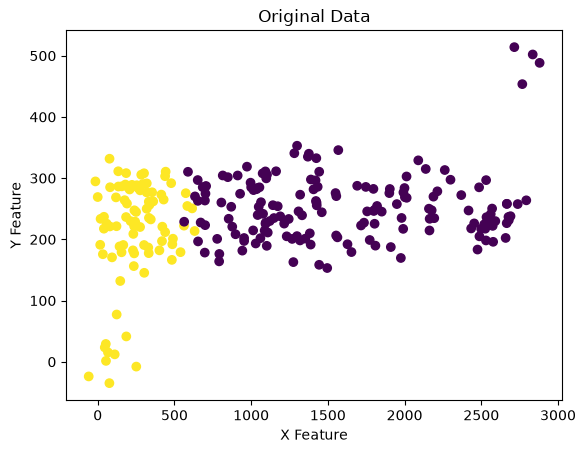

In [6]:
# Plot the original feature distribution.
plt.scatter(X[:, 0], X[:, 1], c=y)

plt.xlabel("X Feature")
plt.ylabel("Y Feature")
plt.title("Original Data")

plt.show()

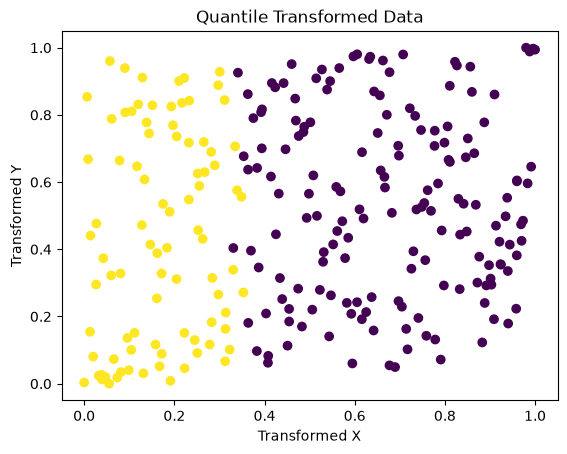

In [7]:
# Transform features and plot their quantiles.
from sklearn.preprocessing import QuantileTransformer

X_new = QuantileTransformer(
    n_quantiles=100
).fit_transform(X)

plt.scatter(X_new[:, 0], X_new[:, 1], c=y)

plt.xlabel("Transformed X")
plt.ylabel("Transformed Y")
plt.title("Quantile Transformed Data")

plt.show()

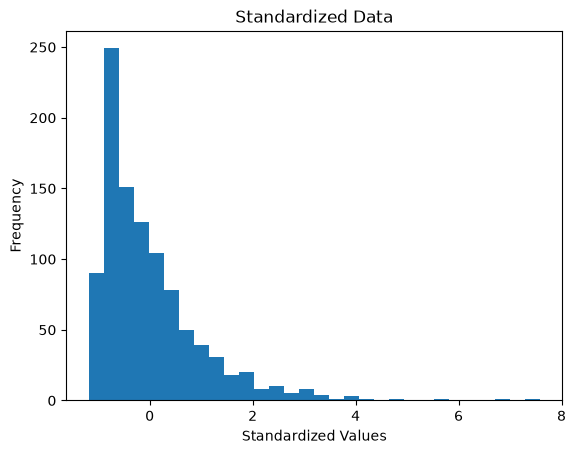

In [8]:
# Generate skewed data and plot standardized values.
x = np.random.exponential(10, (1000)) + np.random.normal(0, 1, (1000))

plt.hist(
    (x - np.mean(x)) / np.std(x),
    bins=30
)

plt.title("Standardized Data")
plt.xlabel("Standardized Values")
plt.ylabel("Frequency")

plt.show()

In [9]:
# Generate another sample of skewed data.
x = np.random.exponential(10, (1000)) + np.random.normal(0, 1, (1000))

(array([ 41., 223., 166., 128., 105.,  86.,  53.,  41.,  34.,  33.,  20.,
         21.,  21.,   3.,   6.,   4.,   5.,   3.,   1.,   3.,   1.,   0.,
          1.,   0.,   0.,   0.,   0.,   0.,   0.,   1.]),
 array([-1.26912003, -0.99319852, -0.71727701, -0.44135549, -0.16543398,
         0.11048753,  0.38640905,  0.66233056,  0.93825208,  1.21417359,
         1.4900951 ,  1.76601662,  2.04193813,  2.31785965,  2.59378116,
         2.86970267,  3.14562419,  3.4215457 ,  3.69746721,  3.97338873,
         4.24931024,  4.52523176,  4.80115327,  5.07707478,  5.3529963 ,
         5.62891781,  5.90483932,  6.18076084,  6.45668235,  6.73260387,
         7.00852538]),
 <BarContainer object of 30 artists>)

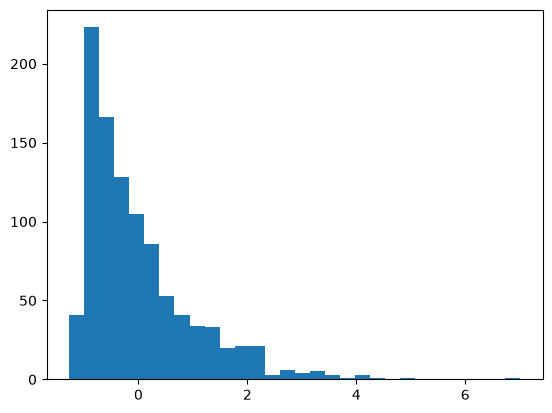

In [13]:
# Plot standardized values as a histogram.
plt.hist((x - np.mean(x)) / np.std(x), bins=30)

In [14]:
# Import preprocessing, classification, and pipeline tools.
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

In [21]:
# Compare original, scaled, and predicted data.

def plot_output(scaler):

    pipe = Pipeline([
        ("scale", scaler),
        ("model", KNeighborsClassifier(
            n_neighbors=20,
            weights="distance"
        )),
    ])

    pred = pipe.fit(X, y).predict(X)

    plt.figure(figsize=(9, 3))

    # Original Data
    plt.subplot(131)
    plt.scatter(X[:, 0], X[:, 1], c=y)
    plt.title("Original Data")

    # Transformed Data
    plt.subplot(132)
    X_tfm = pipe.named_steps["scale"].transform(X)
    plt.scatter(X_tfm[:, 0], X_tfm[:, 1], c=y)
    plt.title("Transformed Data")

    # Predicted Data
    plt.subplot(133)

    X_new = np.concatenate([
        np.random.uniform(0, X[:, 0].max(), (5000, 1)),
        np.random.uniform(0, X[:, 1].max(), (5000, 1))
    ], axis=1)

    y_proba = pipe.predict_proba(X_new)

    plt.scatter(
        X_new[:, 0],
        X_new[:, 1],
        c=y_proba[:, 1],
        alpha=0.7
    )

    plt.title("Predicted Data")
    plt.tight_layout()
    plt.show()


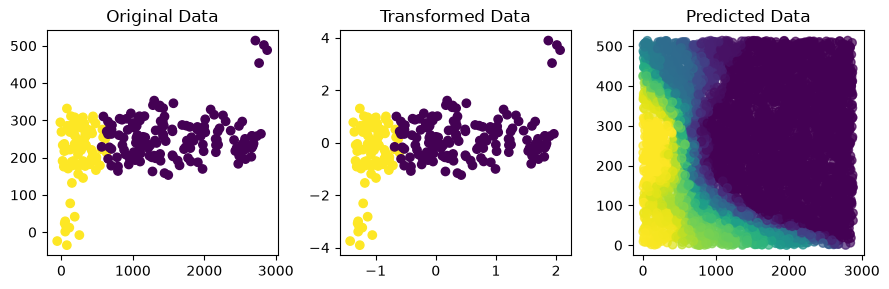

In [22]:
# Visualize data using standard scaling.

plot_output(scaler=StandardScaler())


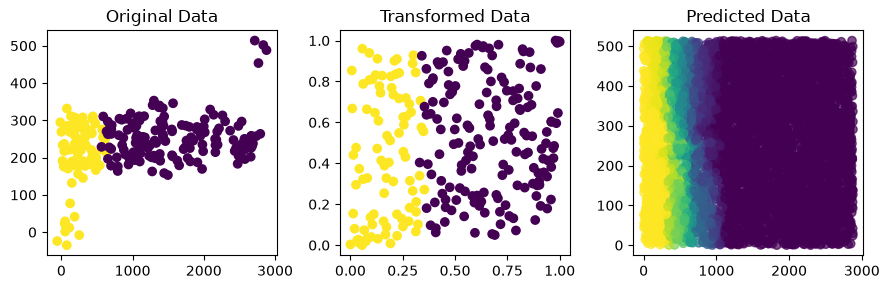

In [23]:
# Visualize data using quantile scaling.

plot_output(
    scaler=QuantileTransformer(n_quantiles=100)
)


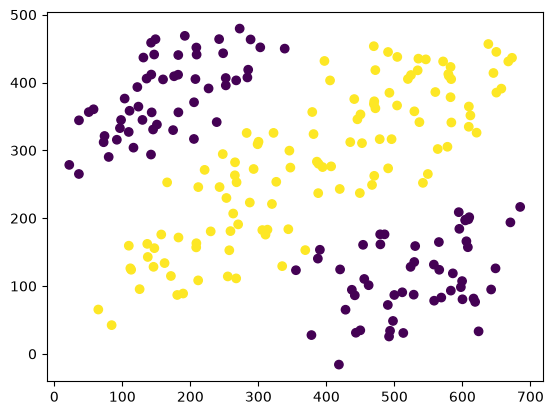

In [24]:
# Load and visualize the second dataset.
df = pd.read_csv("drawndata2.csv")

# Separate features and target
X = df[["x", "y"]].values
y = df["z"] == "a"

# Visualize original data
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

In [25]:
# Import logistic regression.
from sklearn.linear_model import LogisticRegression

In [26]:
# Build a scaled logistic regression pipeline.
pipe = Pipeline([
    ("scale", QuantileTransformer(n_quantiles=100)),
    ("model", LogisticRegression()),
])

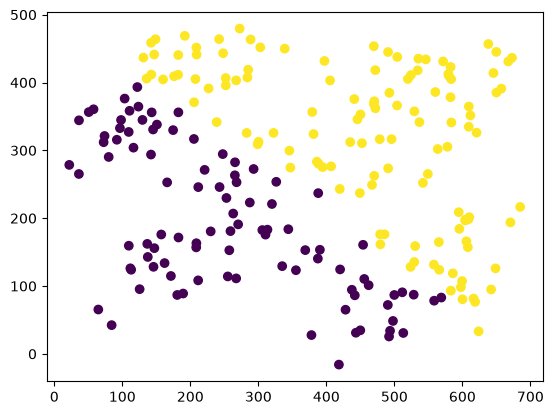

In [27]:
# Fit the pipeline and plot predicted classes.
pred = pipe.fit(X, y).predict(X)

plt.scatter(X[:, 0], X[:, 1], c=pred)
plt.show()

In [28]:
# Import polynomial feature expansion.
from sklearn.preprocessing import PolynomialFeatures

In [29]:
# Build a polynomial logistic regression pipeline.
pipe = Pipeline([
    ("scale", PolynomialFeatures()),
    ("model", LogisticRegression()),
])

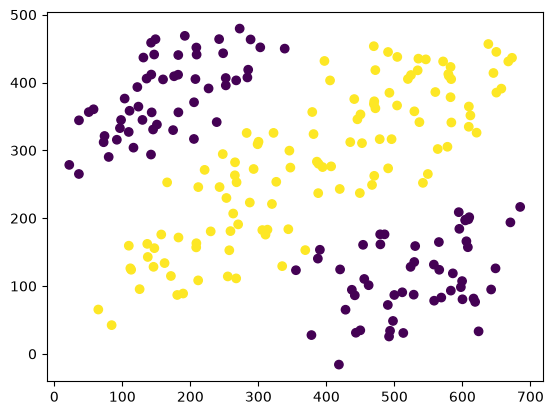

In [30]:
# Fit the pipeline and plot predicted classes.
pred = pipe.fit(X, y).predict(X)

plt.scatter(X[:, 0], X[:, 1], c=pred)
plt.show()

In [31]:
# Create sample categorical values.
arr = np.array([
    "low",
    "low",
    "high",
    "medium"
]).reshape(-1, 1)

print(arr)

[['low']
 ['low']
 ['high']
 ['medium']]


In [32]:
# Import one-hot encoding.
from sklearn.preprocessing import OneHotEncoder

In [33]:
# Configure an encoder to ignore unknown categories.
enc = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

In [34]:
# Encode categories and display the results.
encoded = enc.fit_transform(arr)

print(encoded)

[[0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]]


In [35]:
# Test encoding for an unknown category.
print(enc.transform([["zero"]]))

[[0. 0. 0.]]


In [36]:
# Show the configured unknown-category behavior.
handle_unknown="ignore"